# Khmer Next-Word Prediction — Fine-tuning XLM-R (Stretch Goal, PRD Phase 5)

This notebook is the companion to `script.ipynb` (the LSTM). It **reuses the LSTM run's artifacts on Drive** instead of re-doing preprocessing:
- the cached segmentation (`segmented_nall.jsonl`),
- the same train/val/test article split, recomputed with the LSTM's seed and fractions,
- the LSTM checkpoint's vocabulary.

Run `script.ipynb` (at least through section 9b) first.

### Design: XLM-R as a next-*word* predictor

XLM-R is a bidirectional **masked** language model, not a left-to-right one, so it can't continue a text natively. We ask it to fill a slot at the end of the prefix instead:

```
<s>  ខ្ញុំចង់ទៅ  <mask>  </s>    →   hidden state at <mask>   →   MLM transform   →   softmax over the LSTM's 30k-word vocabulary
```

- **Same targets as the LSTM.** Both models predict a word from the same vocabulary, so perplexity and top-k accuracy are directly comparable.
- **Warm-started word head.** Each word's output vector starts as the mean of XLM-R's embeddings for that word's subword pieces, and the bias starts at the log unigram frequency. Before fine-tuning it is already a sensible zero-shot predictor, which is reported as a baseline.
- **No input OOV.** XLM-R reads the real word strings through its subword tokenizer, so rare words still carry information on the input side. Only the *targets* use `<unk>`.
- **Only the prefix is shown**, so the model's bidirectionality can't leak the answer.

### Fair comparison

Both models (and the unigram baseline) are scored on **one fixed set of (prefix → next word) examples**. The prefix is the start of the current sentence, up to 32 words, which is what a keyboard user has typed. The LSTM's perplexity here will differ somewhat from `script.ipynb`, which scores 32-word chunks that cross sentence boundaries. Compare models **within** this notebook.

## 0. Setup & Configuration

In [21]:
import importlib.util, subprocess, sys

REQUIRED = {"transformers": "transformers", "khmernltk": "khmer-nltk", "tqdm": "tqdm", "matplotlib": "matplotlib"}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [22]:
import json
import math
import os
import random
import re
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass, asdict, replace
from pathlib import Path

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")   # avoid fork warnings/deadlocks with DataLoader workers

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForMaskedLM, AutoTokenizer, get_linear_schedule_with_warmup

IN_COLAB = "google.colab" in sys.modules

In [ ]:
@dataclass
class XLMRConfig:
    # --- what to load ---
    model_name: str = "xlm-roberta-base"      # 278M params; "xlm-roberta-large" (560M) if budget allows
    lstm_run_tag: str = "n300"                # LSTM run to reuse/compare: checkpoints_<tag>/main/best.pt
    # --- examples ---
    max_context_words: int = 32               # same cap for XLM-R and LSTM
    max_input_tokens: int = 128               # subword cap incl. <s> <mask> </s>; truncates from the LEFT
    train_examples_per_epoch: int = 300_000   # fresh random (prefix -> next word) samples each epoch
    eval_examples: int = 20_000               # fixed val/test sets shared by all models
    # --- optimization ---
    epochs: int = 3
    batch_size: int = 64
    encoder_lr: float = 3e-5                  # small LR for pretrained weights
    head_lr: float = 5e-4                     # larger LR for the new word head
    weight_decay: float = 0.01
    warmup_frac: float = 0.06
    grad_clip: float = 1.0
    freeze_embeddings: bool = True            # 250k x 768 input embeddings, mostly non-Khmer: frozen = less memory, smaller checkpoints
    init_head_from_embeddings: bool = True    # warm start (see intro); False = random head, for an ablation
    use_amp: bool = True
    resume: bool = True
    seed: int = 42


xcfg = XLMRConfig()

SMOKE_TEST = False     # tiny numbers to check the pipeline in a few minutes; set False for the real run
if SMOKE_TEST:
    xcfg = replace(xcfg, train_examples_per_epoch=3_000, eval_examples=1_000, epochs=1)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    ARTIFACT_DIR = Path("/content/drive/MyDrive/khmer-autocomplete")
else:
    ARTIFACT_DIR = Path("artifacts")

if xcfg.lstm_run_tag == "n300":
    LSTM_CKPT = ARTIFACT_DIR / f"checkpoints_{xcfg.lstm_run_tag}" / "best.pt"
else:
    LSTM_CKPT = ARTIFACT_DIR / f"checkpoints_{xcfg.lstm_run_tag}" / "main" / "best.pt"
RUN_NAME = f"{xcfg.model_name.split('/')[-1]}_{xcfg.lstm_run_tag}" + ("_smoke" if SMOKE_TEST else "")
XLMR_DIR = ARTIFACT_DIR / "xlmr" / RUN_NAME
XLMR_DIR.mkdir(parents=True, exist_ok=True)
assert LSTM_CKPT.exists(), f"Run script.ipynb first - no LSTM checkpoint at {LSTM_CKPT}"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(xcfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device} | LSTM checkpoint: {LSTM_CKPT} | outputs: {XLMR_DIR}")

Mounted at /content/drive
device: cuda | LSTM checkpoint: /content/drive/MyDrive/khmer-autocomplete/checkpoints_n300/best.pt | outputs: /content/drive/MyDrive/khmer-autocomplete/xlmr/xlm-roberta-base_n300


## 1. Reuse the LSTM Run's Data

The split is recomputed with exactly the LSTM notebook's code, seed and fractions, all read from the LSTM checkpoint's saved config. As a check, the vocabulary is rebuilt from the recomputed train split and compared with the checkpoint's. An exact match proves both notebooks use the same split.

In [24]:
lstm_ckpt = torch.load(LSTM_CKPT, map_location="cpu")
lcfg = lstm_ckpt["config"]
itos = lstm_ckpt["vocab"]
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK, EOS, NUM = "<pad>", "<unk>", "<eos>", "<num>"
pad_id, unk_id, eos_id = stoi[PAD], stoi[UNK], stoi[EOS]
special_ids = torch.tensor([pad_id, unk_id, eos_id])
V = len(itos)
print(f"LSTM vocab: {V:,} words | LSTM config: hidden={lcfg['hidden_dim']} layers={lcfg['num_layers']} "
      f"embed={lcfg['embed_dim']} extra_docs={lcfg.get('extra_docs', 0)}")

SEG_CACHE = ARTIFACT_DIR / f"segmented_n{lcfg['max_articles'] or 'all'}.jsonl"


def load_segmented(path):
    out = {}
    with path.open(encoding="utf-8") as f:
        for line in f:
            try:
                rec = json.loads(line)
            except json.JSONDecodeError:
                continue
            out[rec["id"]] = [[sys.intern(w) for w in s] for s in rec["sentences"]]   # intern: ~7M tokens fit in RAM
    return out


segmented = load_segmented(SEG_CACHE)

# --- identical to script.ipynb section 4 ---
article_ids = sorted(segmented)
random.Random(lcfg["seed"]).shuffle(article_ids)
n_val = max(1, int(len(article_ids) * lcfg["val_frac"]))
n_test = max(1, int(len(article_ids) * lcfg["test_frac"]))
split_ids = {
    "val": article_ids[:n_val],
    "test": article_ids[n_val:n_val + n_test],
    "train": article_ids[n_val + n_test:],
}
splits = {name: [s for aid in ids for s in segmented[aid]] for name, ids in split_ids.items()}
for name, sents in splits.items():
    print(f"{name:>5}: {len(split_ids[name]):>6,} articles | {len(sents):>8,} sentences | {sum(map(len, sents)):>10,} tokens")

# --- sanity check: rebuilt vocab == LSTM vocab ---
train_counts = Counter(w for s in splits["train"] for w in s)
rebuilt = [w for w, c in train_counts.most_common(lcfg["max_vocab"] - 3) if c >= lcfg["min_freq"]]
if rebuilt == itos[3:]:
    print("✓ Split verified: rebuilt vocabulary matches the LSTM checkpoint exactly.")
else:
    print("⚠ Rebuilt vocab differs from the LSTM's (expected if the LSTM used extra_docs). "
          "Val/test are still the same Wikipedia articles; XLM-R trains on Wikipedia only.")

LSTM vocab: 5,064 words | LSTM config: hidden=512 layers=2 embed=256 extra_docs=0
  val:     15 articles |      733 sentences |     15,827 tokens
 test:     15 articles |      421 sentences |      8,638 tokens
train:    270 articles |    7,359 sentences |    156,358 tokens
✓ Split verified: rebuilt vocabulary matches the LSTM checkpoint exactly.


## 2. Examples: (sentence prefix → next word)

An example is a sentence position `k`. The context is the first `k` words of the sentence (only the last `max_context_words − 1` if the sentence is longer), and the target is word `k`, or `<eos>` at the end of the sentence. Positions are sampled uniformly over all tokens, so the mix of short and long prefixes matches real text.

The two models see the same example differently:
- **LSTM:** `[<eos>] + word ids`. A leading `<eos>` marks "start of sentence", exactly as in its training and in the demo.
- **XLM-R:** the context words joined back into natural Khmer text (no spaces, `<num>` → `១`), then `<s> … <mask> </s>`.

In [25]:
C = xcfg.max_context_words
SURFACE = {EOS: "។", NUM: "១", PAD: ""}          # how special tokens look as text (UNK filled in after tokenizer loads)


def make_example(sentences, sent_idx, k):
    s = sentences[sent_idx]
    start = max(0, k - (C - 1))
    target = s[k] if k < len(s) else EOS
    return s[start:k], start == 0, stoi.get(target, unk_id), k


def sample_positions(sentences, n, seed):
    lens = np.fromiter((len(s) + 1 for s in sentences), dtype=np.int64, count=len(sentences))   # +1 for the <eos> target
    cum = np.cumsum(lens)
    rng = np.random.default_rng(seed)
    flat = rng.choice(int(cum[-1]), size=min(n, int(cum[-1])), replace=False)
    sent = np.searchsorted(cum, flat, side="right")
    k = flat - (cum[sent] - lens[sent])
    return np.stack([sent, k], axis=1)


class NextWordDataset(Dataset):
    def __init__(self, sentences, positions):
        self.sentences, self.positions = sentences, positions

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, i):
        s, k = self.positions[i]
        return make_example(self.sentences, int(s), int(k))


# Fixed evaluation sets, shared by every model in this notebook (saved for reproducibility).
eval_sets = {name: NextWordDataset(splits[name], sample_positions(splits[name], xcfg.eval_examples, seed=1000 + i))
             for i, name in enumerate(("val", "test"))}
with open(XLMR_DIR / "eval_positions.json", "w") as f:
    json.dump({name: ds.positions.tolist() for name, ds in eval_sets.items()}, f)

for i in range(3):
    ctx, at_start, y, k = eval_sets["val"][i]
    print(f"k={k:<3} context: {' '.join(ctx[-8:]) or '<sentence start>':<60} -> {itos[y]}")

k=17  context: សម្រាប់ ការគ្រប់គ្រង តំបន់ នៅ អាស៊ី ខាងក្នុង និង កណ្តាល      -> <eos>
k=28  context: អឺរ៉ុប ឥណ្ឌា និង ចិន ដែល ផ្អែក លើ សង្គម                      -> របស់
k=40  context: បន្តិច ក៏ ឋិតនៅ ជាន់ ទី២ តាម លំដាប់ រៀង                      -> ដល់


## 3. Tokenizer & Batching for XLM-R

In [26]:
tokenizer = AutoTokenizer.from_pretrained(xcfg.model_name)
SURFACE[UNK] = tokenizer.unk_token
CLS, SEP, MASK, TOK_PAD = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.mask_token_id, tokenizer.pad_token_id


def words_to_text(words):
    return "".join(SURFACE.get(w, w) for w in words)


def collate_xlmr(batch):
    ctxs, _, targets, ks = zip(*batch)
    pieces = tokenizer([words_to_text(c) for c in ctxs], add_special_tokens=False)["input_ids"]
    keep = xcfg.max_input_tokens - 3
    seqs = [[CLS] + (p[-keep:] if p else []) + [MASK, SEP] for p in pieces]     # keep the END of long prefixes
    input_ids = torch.full((len(seqs), max(map(len, seqs))), TOK_PAD, dtype=torch.long)
    attention = torch.zeros_like(input_ids)
    for i, s in enumerate(seqs):
        input_ids[i, :len(s)] = torch.tensor(s)
        attention[i, :len(s)] = 1
    mask_pos = torch.tensor([len(s) - 2 for s in seqs])
    return input_ids, attention, mask_pos, torch.tensor(targets), torch.tensor(ks)


ids, att, mpos, y, ks = collate_xlmr([eval_sets["val"][i] for i in range(2)])
for row, p in zip(ids, mpos):
    toks = tokenizer.convert_ids_to_tokens(row[:p + 2].tolist())
    print(" ".join(toks[-12:]))

lengths = [len(collate_xlmr([eval_sets["val"][i]])[0][0]) for i in range(min(500, len(eval_sets["val"])))]
print(f"\nInput length (subwords incl. specials): median {int(np.median(lengths))}, "
      f"95th pct {int(np.percentile(lengths, 95))}, max {max(lengths)} (cap {xcfg.max_input_tokens})")

សម្រាប់ ការ គ្រប់គ្រង តំបន់ នៅ អាស៊ី ខាង ក្នុង និង កណ្តាល <mask> </s>
អឺរ៉ុប ឥណ្ឌា និង ចិន ដែល ផ្ អ ែក លើ សង្គម <mask> </s>

Input length (subwords incl. specials): median 23, 95th pct 54, max 73 (cap 128)


## 4. Model

`XLM-R encoder → hidden state at <mask> → XLM-R's own MLM transform (dense → GELU → LayerNorm) → word head (V × hidden) + bias`

Reusing the pretrained MLM transform keeps the `<mask>` representation in the space the word head was initialized from.

In [27]:
class XLMRNextWord(nn.Module):
    def __init__(self, model_name, vocab_size):
        super().__init__()
        mlm = AutoModelForMaskedLM.from_pretrained(model_name)
        self.encoder = mlm.base_model
        self.dense, self.layer_norm = mlm.lm_head.dense, mlm.lm_head.layer_norm
        hidden = mlm.config.hidden_size
        self.word_emb = nn.Parameter(torch.empty(vocab_size, hidden).normal_(0, 0.02))
        self.word_bias = nn.Parameter(torch.zeros(vocab_size))

    def forward(self, input_ids, attention_mask, mask_pos):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        h = h[torch.arange(h.size(0), device=h.device), mask_pos]
        h = self.layer_norm(F.gelu(self.dense(h)))
        return h @ self.word_emb.T + self.word_bias


def unigram_log_probs():
    counts = torch.zeros(V)
    for w, c in train_counts.items():
        counts[stoi.get(w, unk_id)] += c
    counts[eos_id] += len(splits["train"])          # one <eos> target per sentence
    counts += 1.0
    counts[pad_id] = 0.0
    return (counts / counts.sum()).log()


@torch.no_grad()
def init_word_head(model):
    emb = model.encoder.get_input_embeddings().weight.detach().float().cpu()
    blank = tokenizer.convert_tokens_to_ids("▁")                 # bare word-start marker carries no meaning
    pieces = tokenizer([words_to_text([w]) for w in itos], add_special_tokens=False)["input_ids"]
    pieces = [[t for t in p if t != blank] for p in pieces]
    rows = torch.tensor([i for i, p in enumerate(pieces) for _ in p], dtype=torch.long)
    cols = torch.tensor([t for p in pieces for t in p], dtype=torch.long)
    sums = torch.zeros(V, emb.size(1)).index_add_(0, rows, emb[cols])
    counts = torch.bincount(rows, minlength=V)
    has = counts > 0
    model.word_emb[has] = (sums[has] / counts[has, None]).to(model.word_emb)
    model.word_bias.copy_(unigram_log_probs().clamp(min=-30).to(model.word_bias))   # pad: -inf -> large negative
    print(f"Word head initialized from subword embeddings for {int(has.sum()):,}/{V:,} words")


FROZEN = {"encoder.embeddings.word_embeddings.weight"} if xcfg.freeze_embeddings else set()


def build_xlmr():
    m = XLMRNextWord(xcfg.model_name, V)
    for n, p in m.named_parameters():
        p.requires_grad = n not in FROZEN
    if xcfg.init_head_from_embeddings:
        init_word_head(m)
    return m.to(device)


def trainable_state(m):
    return {n: t for n, t in m.state_dict().items() if n not in FROZEN}


def load_trainable_state(m, state):
    missing, unexpected = m.load_state_dict(state, strict=False)
    assert set(missing) <= FROZEN and not unexpected, (missing, unexpected)


xlmr = build_xlmr()
n_total = sum(p.numel() for p in xlmr.parameters())
n_train = sum(p.numel() for p in xlmr.parameters() if p.requires_grad)
print(f"Parameters: {n_total:,} total | {n_train:,} trainable")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Word head initialized from subword embeddings for 5,063/5,064 words
Parameters: 281,939,400 total | 89,937,864 trainable


## 5. Shared Metrics

These are the same definitions as `script.ipynb`: perplexity over all targets, plus top-k accuracy in an **all** view and a **words** view (no `<unk>`/`<eos>` targets, no special tokens suggested). Scores are kept per example, so results can also be broken down by **prefix length**, i.e. how many words of the sentence the user has typed.

In [28]:
TOP_KS = (1, 3, 5)
LEN_BUCKETS = [(0, 0, "0 (sentence start)"), (1, 2, "1-2"), (3, 5, "3-5"), (6, 10, "6-10"), (11, 10**9, "11+")]


def amp_ctx():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=xcfg.use_amp and device.type == "cuda")


class Scores:
    # Per-example metrics, accumulated batch by batch.
    def __init__(self):
        self.parts = {}

    def add(self, logits, y, ks):
        logits, y = logits.float(), y.to(logits.device)
        sids = special_ids.to(logits.device)
        max_k = max(TOP_KS)
        top = logits.topk(max_k, dim=-1).indices == y[:, None]
        masked = logits.clone()
        masked[:, sids] = float("-inf")
        top_w = masked.topk(max_k, dim=-1).indices == y[:, None]
        cols = {"nll": F.cross_entropy(logits, y, reduction="none"), "ctx_len": ks.to(logits.device),
                "is_word": ~torch.isin(y, sids)}
        for k in TOP_KS:
            cols[f"top{k}_all"] = top[:, :k].any(1)
            cols[f"top{k}_words"] = top_w[:, :k].any(1)
        for name, v in cols.items():
            self.parts.setdefault(name, []).append(v.cpu())

    def arrays(self):
        return {n: torch.cat(v).numpy() for n, v in self.parts.items()}

    def summary(self, select=None):
        a = self.arrays()
        sel = np.ones(len(a["nll"]), bool) if select is None else select(a)
        w = sel & a["is_word"]
        out = {"ppl": float(np.exp(a["nll"][sel].mean())), "n": int(sel.sum())}
        for k in TOP_KS:
            out[f"top{k}_all"] = float(a[f"top{k}_all"][sel].mean())
            out[f"top{k}_words"] = float(a[f"top{k}_words"][w].mean()) if w.any() else float("nan")
        return out

    def by_length(self):
        return {label: self.summary(lambda a, lo=lo, hi=hi: (a["ctx_len"] >= lo) & (a["ctx_len"] <= hi))
                for lo, hi, label in LEN_BUCKETS}


def fmt(m):
    return " | ".join(f"{k} {v:.2f}" if k == "ppl" else f"{k} {v:.1%}" for k, v in m.items() if k != "n")


@torch.no_grad()
def eval_xlmr(model, dataset, desc="eval"):
    model.eval()
    scores = Scores()
    loader = DataLoader(dataset, batch_size=xcfg.batch_size * 2, shuffle=False, collate_fn=collate_xlmr)
    for input_ids, att, mpos, y, ks in tqdm(loader, desc=desc, leave=False):
        with amp_ctx():
            logits = model(input_ids.to(device), att.to(device), mpos.to(device))
        scores.add(logits, y, ks)
    return scores


@torch.no_grad()
def eval_unigram(dataset):
    log_probs = unigram_log_probs()
    scores = Scores()
    for i in range(0, len(dataset), 4096):
        batch = [dataset[j] for j in range(i, min(i + 4096, len(dataset)))]
        y = torch.tensor([b[2] for b in batch])
        scores.add(log_probs.expand(len(batch), -1), y, torch.tensor([b[3] for b in batch]))
    return scores


results = {"val": {}, "test": {}}
results["val"]["unigram"] = eval_unigram(eval_sets["val"])
results["val"]["xlmr_zero_shot"] = eval_xlmr(xlmr, eval_sets["val"], "zero-shot")
for name, s in results["val"].items():
    print(f"{name:<16} (val): {fmt(s.summary())}")

zero-shot:   0%|          | 0/130 [00:00<?, ?it/s]

unigram          (val): ppl 580.31 | top1_all 9.1% | top1_words 3.1% | top3_all 16.2% | top3_words 8.0% | top5_all 20.4% | top5_words 12.0%
xlmr_zero_shot   (val): ppl 4127.20 | top1_all 7.3% | top1_words 10.4% | top3_all 18.6% | top3_words 18.1% | top5_all 24.2% | top5_words 22.9%


## 6. Fine-tuning

- **Two learning rates.** The pretrained encoder gets a small one (`encoder_lr`) and the new word head a larger one (`head_lr`). Linear warmup, then linear decay.
- **Fresh examples every epoch.** Each epoch samples `train_examples_per_epoch` new prefix positions from the training split. That's cheaper than visiting every position, which a bidirectional model would have to do with one forward pass per prefix.
- **Mixed precision, gradient clipping, and a checkpoint every epoch.** `last.pt` holds the trainable weights, optimizer, scheduler and history, so a Colab drop resumes at the last finished epoch. `best.pt` holds weights only. Frozen input embeddings aren't saved, which keeps files around 0.5 GB (best) and 1.3 GB (last) for `xlm-roberta-base`.

On a Colab T4, budget roughly **15–25 minutes per 300k examples** with `xlm-roberta-base`. Check the first epoch's timing before committing to more.

In [29]:
def param_groups(model):
    no_decay = lambda n: n.endswith("bias") or "LayerNorm" in n or "layer_norm" in n
    groups = {(True, True): [], (True, False): [], (False, True): [], (False, False): []}
    for n, p in model.named_parameters():
        if p.requires_grad:
            groups[(n.startswith("encoder."), no_decay(n))].append(p)
    return [{"params": ps, "lr": xcfg.encoder_lr if enc else xcfg.head_lr, "weight_decay": 0.0 if nd else xcfg.weight_decay}
            for (enc, nd), ps in groups.items() if ps]


steps_per_epoch = xcfg.train_examples_per_epoch // xcfg.batch_size
optimizer = torch.optim.AdamW(param_groups(xlmr))
scheduler = get_linear_schedule_with_warmup(optimizer, int(xcfg.warmup_frac * steps_per_epoch * xcfg.epochs),
                                            steps_per_epoch * xcfg.epochs)
scaler = torch.amp.GradScaler("cuda", enabled=xcfg.use_amp and device.type == "cuda")
LAST, BEST = XLMR_DIR / "last.pt", XLMR_DIR / "best.pt"

start_epoch, best_val_ppl, history = 0, float("inf"), []
if xcfg.resume and LAST.exists():
    ckpt = torch.load(LAST, map_location=device)
    if ckpt["config"] == asdict(xcfg) and ckpt["vocab"] == itos:
        load_trainable_state(xlmr, ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        if ckpt["scaler"]:
            scaler.load_state_dict(ckpt["scaler"])
        start_epoch, best_val_ppl, history = ckpt["epoch"] + 1, ckpt["best_val_ppl"], ckpt["history"]
        print(f"Resumed after epoch {start_epoch} (best val ppl {best_val_ppl:.2f})")
    else:
        print("Checkpoint config/vocab differs - starting fresh.")

for epoch in range(start_epoch, xcfg.epochs):
    train_ds = NextWordDataset(splits["train"], sample_positions(splits["train"], xcfg.train_examples_per_epoch,
                                                                 seed=xcfg.seed + epoch))
    loader = DataLoader(train_ds, batch_size=xcfg.batch_size, shuffle=True, drop_last=True,
                        collate_fn=collate_xlmr, num_workers=2 if IN_COLAB else 0)
    xlmr.train()
    t0, total, n = time.time(), 0.0, 0
    pbar = tqdm(loader, desc=f"epoch {epoch + 1}/{xcfg.epochs}")
    for input_ids, att, mpos, y, _ in pbar:
        optimizer.zero_grad(set_to_none=True)
        with amp_ctx():
            logits = xlmr(input_ids.to(device), att.to(device), mpos.to(device))
            loss = F.cross_entropy(logits.float(), y.to(device))
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_([p for p in xlmr.parameters() if p.requires_grad], xcfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total, n = total + loss.item(), n + 1
        if n % 50 == 0:
            pbar.set_postfix(ppl=f"{math.exp(total / n):.1f}")

    val = eval_xlmr(xlmr, eval_sets["val"]).summary()
    history.append({"epoch": epoch + 1, "train_ppl": math.exp(total / max(n, 1)), **val, "minutes": (time.time() - t0) / 60})
    print(f"epoch {epoch + 1} | {(time.time() - t0) / 60:.1f} min | train ppl {history[-1]['train_ppl']:.2f} | val {fmt(val)}")

    if val["ppl"] < best_val_ppl:
        best_val_ppl = val["ppl"]
        torch.save({"model": trainable_state(xlmr), "config": asdict(xcfg), "vocab": itos}, BEST)
    torch.save({"model": trainable_state(xlmr), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "best_val_ppl": best_val_ppl, "history": history,
                "config": asdict(xcfg), "vocab": itos}, LAST)

if BEST.exists():
    load_trainable_state(xlmr, torch.load(BEST, map_location=device)["model"])
    print(f"Loaded best XLM-R weights (val ppl {best_val_ppl:.2f})")

epoch 1/3:   0%|          | 0/2558 [00:00<?, ?it/s]

/tmp/ipykernel_1305/1032440864.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


eval:   0%|          | 0/130 [00:00<?, ?it/s]

epoch 1 | 9.6 min | train ppl 196.44 | val ppl 112.11 | top1_all 20.4% | top1_words 18.2% | top3_all 34.1% | top3_words 29.5% | top5_all 40.6% | top5_words 35.8%


epoch 2/3:   0%|          | 0/2558 [00:00<?, ?it/s]

eval:   0%|          | 0/130 [00:00<?, ?it/s]

epoch 2 | 9.6 min | train ppl 67.37 | val ppl 100.46 | top1_all 21.2% | top1_words 19.4% | top3_all 35.5% | top3_words 31.7% | top5_all 42.3% | top5_words 38.1%


epoch 3/3:   0%|          | 0/2558 [00:00<?, ?it/s]

eval:   0%|          | 0/130 [00:00<?, ?it/s]

epoch 3 | 9.6 min | train ppl 34.24 | val ppl 104.94 | top1_all 21.7% | top1_words 19.7% | top3_all 35.2% | top3_words 31.3% | top5_all 42.2% | top5_words 37.6%
Loaded best XLM-R weights (val ppl 100.46)


## 7. LSTM on the Same Examples

The class definition must match `script.ipynb` so the checkpoint loads. The LSTM sees `[<eos>] + prefix ids`, and examples are grouped by length so batches need no padding.

In [30]:
class LSTMLanguageModel(nn.Module):        # identical to script.ipynb (embedding dropout is training-only, so omitted)
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout, tie_weights, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        out_dim, self.proj = hidden_dim, None
        if tie_weights and hidden_dim != embed_dim:
            self.proj = nn.Linear(hidden_dim, embed_dim)
            out_dim = embed_dim
        self.decoder = nn.Linear(out_dim, vocab_size)
        if tie_weights:
            self.decoder.weight = self.embedding.weight

    def forward(self, x, hidden=None):
        out, hidden = self.lstm(self.drop(self.embedding(x)), hidden)
        out = self.drop(out)
        if self.proj is not None:
            out = self.proj(out)
        return self.decoder(out), hidden


lstm = LSTMLanguageModel(V, lcfg["embed_dim"], lcfg["hidden_dim"], lcfg["num_layers"], lcfg["dropout"],
                         lcfg["tie_weights"], pad_id).to(device)
lstm.load_state_dict(lstm_ckpt["model"])
lstm.eval()


def lstm_input(ctx, at_start):
    return ([eos_id] if at_start else []) + [stoi.get(w, unk_id) for w in ctx]


@torch.no_grad()
def eval_lstm(model, dataset, batch_size=512):
    examples = [dataset[i] for i in range(len(dataset))]
    by_len = {}
    for ctx, at_start, y, k in examples:
        ids = lstm_input(ctx, at_start)
        by_len.setdefault(len(ids), []).append((ids, y, k))
    scores = Scores()
    for group in by_len.values():
        for i in range(0, len(group), batch_size):
            chunk = group[i:i + batch_size]
            x = torch.tensor([c[0] for c in chunk], device=device)
            with amp_ctx():
                logits, _ = model(x)
            scores.add(logits[:, -1], torch.tensor([c[1] for c in chunk]), torch.tensor([c[2] for c in chunk]))
    return scores


results["val"]["lstm"] = eval_lstm(lstm, eval_sets["val"])
results["val"]["xlmr_finetuned"] = eval_xlmr(xlmr, eval_sets["val"], "fine-tuned")
for name in ("lstm", "xlmr_finetuned"):
    print(f"{name:<16} (val): {fmt(results['val'][name].summary())}")

fine-tuned:   0%|          | 0/130 [00:00<?, ?it/s]

lstm             (val): ppl 233.93 | top1_all 17.4% | top1_words 14.3% | top3_all 28.6% | top3_words 23.3% | top5_all 34.5% | top5_words 28.4%
xlmr_finetuned   (val): ppl 100.46 | top1_all 21.2% | top1_words 19.4% | top3_all 35.5% | top3_words 31.7% | top5_all 42.3% | top5_words 38.1%


## 8. Final Comparison on the Test Set (PRD Phase 5)

The PRD's stretch criterion is that the transformer shows a measurable improvement in perplexity or top-k accuracy over the LSTM.

- **Overall:** all models on the same test examples.
- **By prefix length:** shows *where* each model wins. For a keyboard, the short prefixes (0–5 words) matter most.

In [31]:
xlmr_zero = build_xlmr()                       # fresh warm-started head, no fine-tuning
results["test"] = {
    "unigram": eval_unigram(eval_sets["test"]),
    "lstm": eval_lstm(lstm, eval_sets["test"]),
    "xlmr_zero_shot": eval_xlmr(xlmr_zero, eval_sets["test"], "zero-shot"),
    "xlmr_finetuned": eval_xlmr(xlmr, eval_sets["test"], "fine-tuned"),
}
del xlmr_zero
if device.type == "cuda":
    torch.cuda.empty_cache()

cols = ["ppl"] + [f"top{k}_words" for k in TOP_KS] + [f"top{k}_all" for k in TOP_KS]
print(f"{'model':<16}" + "".join(f"{c:>13}" for c in cols))
summaries = {name: s.summary() for name, s in results["test"].items()}
for name, m in summaries.items():
    print(f"{name:<16}" + "".join(f"{m[c]:>13.2f}" if c == "ppl" else f"{m[c]:>13.1%}" for c in cols))

print(f"\nTop-3 accuracy (words view) by prefix length:")
buckets = {name: s.by_length() for name, s in results["test"].items()}
print(f"{'prefix words':<20}{'n':>7}" + "".join(f"{name:>16}" for name in buckets))
for _, _, label in LEN_BUCKETS:
    n = buckets["lstm"][label]["n"]
    print(f"{label:<20}{n:>7}" + "".join(f"{buckets[name][label]['top3_words']:>16.1%}" for name in buckets))

with open(XLMR_DIR / "test_comparison.json", "w") as f:
    json.dump({"overall": summaries, "by_prefix_length": buckets, "history": history, "config": asdict(xcfg)}, f, indent=2)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Word head initialized from subword embeddings for 5,063/5,064 words


zero-shot:   0%|          | 0/71 [00:00<?, ?it/s]

fine-tuned:   0%|          | 0/71 [00:00<?, ?it/s]

model                     ppl   top1_words   top3_words   top5_words     top1_all     top3_all     top5_all
unigram                564.32         3.4%         8.0%        11.1%        10.1%        17.7%        21.6%
lstm                   210.84        14.5%        24.0%        29.0%        18.0%        29.6%        35.9%
xlmr_zero_shot        4048.27         9.1%        17.3%        22.3%         7.4%        18.1%        23.7%
xlmr_finetuned          90.18        20.3%        32.2%        38.2%        22.4%        36.8%        43.4%

Top-3 accuracy (words view) by prefix length:
prefix words              n         unigram            lstm  xlmr_zero_shot  xlmr_finetuned
0 (sentence start)      421            2.3%           17.5%            0.0%           15.9%
1-2                     842           13.1%           32.1%            9.6%           39.0%
3-5                    1198           10.9%           24.9%           16.2%           31.8%
6-10                   1698            8.6%  

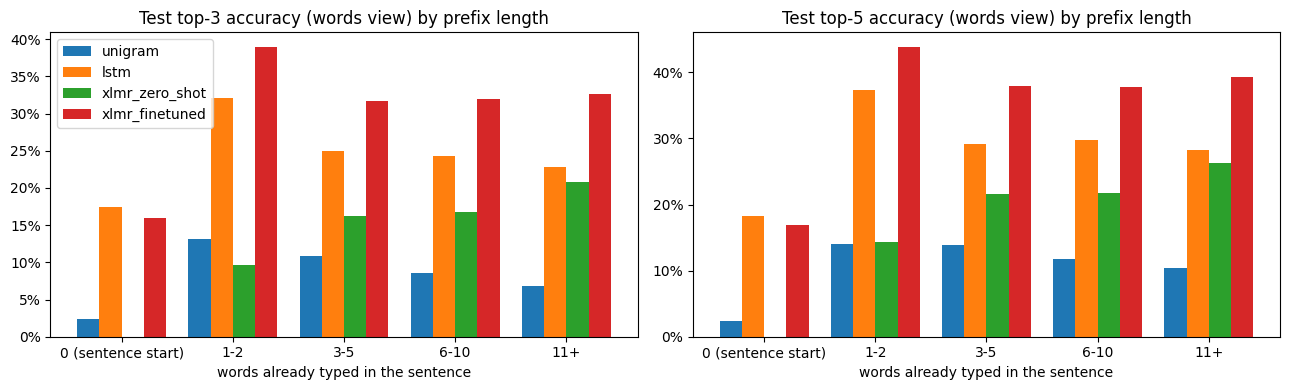

In [32]:
labels = [b[2] for b in LEN_BUCKETS]
xs = np.arange(len(labels))
width = 0.8 / len(buckets)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (name, b) in enumerate(buckets.items()):
    for ax, k in zip(axes, (3, 5)):
        ax.bar(xs + i * width, [b[l][f"top{k}_words"] for l in labels], width, label=name)
for ax, k in zip(axes, (3, 5)):
    ax.set(title=f"Test top-{k} accuracy (words view) by prefix length", xlabel="words already typed in the sentence",
           xticks=xs + width * (len(buckets) - 1) / 2, xticklabels=labels, ylim=(0, None))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend()
plt.tight_layout()
plt.show()

## 9. Side-by-side Suggestions (groundwork for FR6: model switching in the demo)

Uses the same clean → segment pipeline as `script.ipynb`, so typed text is handled identically for both models.

In [33]:
from khmernltk import word_tokenize

SENT_SPLIT_RE = re.compile(r"[\n។៕?!]+")
INVISIBLE_RE = re.compile(r"[‌‍﻿­឴឵]")
KHMER_PUNCT_RE = re.compile(r"[៖៘-៚]")
NON_KHMER_RE = re.compile(r"[^ក-៿᧠-᧿0-9\s]+")
KHMER_CHAR_RE = re.compile(r"[ក-៿᧠-᧿]")
DIGIT_RE = re.compile(r"[0-9០-៩]+")
WS_RE = re.compile(r"\s+")


def current_sentence_words(text):
    # Words of the sentence being typed (empty if the text ends with sentence punctuation).
    text = INVISIBLE_RE.sub("", unicodedata.normalize("NFC", text).replace("​", " "))
    if not text.strip() or SENT_SPLIT_RE.fullmatch(text.rstrip()[-1:]):
        return []
    last = SENT_SPLIT_RE.split(text)[-1]
    last = WS_RE.sub(" ", KHMER_PUNCT_RE.sub(" ", NON_KHMER_RE.sub(" ", last))).strip()
    if not KHMER_CHAR_RE.search(last):
        return []
    words = []
    for tok in word_tokenize(last, return_tokens=True):
        tok = tok.strip()
        if not tok:
            continue
        if DIGIT_RE.fullmatch(tok):
            if words and words[-1] == NUM:
                continue
            tok = NUM
        words.append(tok)
    return words


BLOCKED = [pad_id, unk_id, eos_id] + ([stoi[NUM]] if NUM in stoi else [])


@torch.no_grad()
def suggest(text, model_name="xlmr", k=5):
    words = current_sentence_words(text)
    ctx = words[-(C - 1):]
    at_start = len(words) <= C - 1
    if model_name == "xlmr":
        xlmr.eval()
        input_ids, att, mpos, _, _ = collate_xlmr([(ctx, at_start, 0, len(ctx))])
        logits = xlmr(input_ids.to(device), att.to(device), mpos.to(device))[0]
    else:
        logits, _ = lstm(torch.tensor([lstm_input(ctx, at_start)], device=device))
        logits = logits[0, -1]
    probs = logits.float().softmax(-1)
    probs[BLOCKED] = 0.0
    top = probs.topk(k)
    return [(itos[i], p) for i, p in zip(top.indices.tolist(), top.values.tolist())]


for text in ["", "ខ្ញុំចង់ទៅ", "ប្រទេសកម្ពុជា", "រាជធានីភ្នំពេញ", "ក្នុងឆ្នាំ ២០២៣"]:
    print(f"{text or '<empty>'}")
    for m in ("lstm", "xlmr"):
        print(f"   {m:<5} -> " + "  ".join(f"{w} ({p:.0%})" for w, p in suggest(text, m)))

<empty>
   lstm  -> នៅ (3%)  ក្នុង (1%)  អ្នក (1%)  សូម (1%)  បន្ទាប់ពី (1%)
   xlmr  -> នៅ (3%)  ឧកញ៉ា (1%)  បើ (1%)  ជា (1%)  ក្នុង (1%)
ខ្ញុំចង់ទៅ
   lstm  -> ជួយ (11%)  វិញ (7%)  ផង (4%)  រក (3%)  មើល (2%)
   xlmr  -> តាម (9%)  សិក្សា (7%)  នៅ (6%)  ទស្សនា (4%)  រៀន (3%)
ប្រទេសកម្ពុជា
   lstm  -> បាន (12%)  ដែល (5%)  មាន (5%)  គឺជា (5%)  នៅ (3%)
   xlmr  -> ជា (19%)  មាន (13%)  បាន (12%)  គឺជា (8%)  ត្រូវបាន (2%)
រាជធានីភ្នំពេញ
   lstm  -> ព្រះរាជាណាចក្រ (10%)  បាន (9%)  មាន (7%)  កម្ពុជា (2%)  ជា (2%)
   xlmr  -> មាន (20%)  គឺជា (12%)  ជា (9%)  បាន (7%)  ត្រូវបាន (4%)
ក្នុងឆ្នាំ ២០២៣
   lstm  -> លោក (3%)  មាន (2%)  និង (2%)  ចក្រភព (2%)  ព្រះបាទ (2%)
   xlmr  -> លោក (18%)  រុស្ស៊ី (5%)  ព្រះអង្គ (4%)  បាន (2%)  មាន (2%)


## Next Steps

- [ ] Check the pipeline with `SMOKE_TEST = True`, then set it to `False` and run for real. Look at the first epoch's minutes and val ppl before deciding on more epochs or examples.
- [ ] **If fine-tuned XLM-R doesn't beat the LSTM**, try in this order: more `train_examples_per_epoch` (the LSTM sees every position every epoch, XLM-R only a sample), `head_lr` 1e-3, `encoder_lr` 5e-5, and `freeze_embeddings=False`.
- [ ] Ablation for the report: `init_head_from_embeddings=False` shows how much the warm start contributes.
- [ ] Optional: `xlm-roberta-large` (slower; reduce `batch_size` to 16–32).
- [ ] FR6: add a model switch to `streamlit_app.py` using `suggest(text, model_name)`. Note that XLM-R inference on CPU is much slower than the LSTM.
- [ ] For the report: XLM-R is a masked LM used through a `<mask>` slot. A multilingual decoder-only LM whose pretraining covers Khmer is the natural alternative architecture, worth mentioning as future work.